# 04 — Full-panel model evaluation

Compare all 30,490 series on common forecast windows; the previously inspected local test is retrospective.

## Imports

In [1]:
from pathlib import Path
from types import SimpleNamespace
import os, json, time, warnings
import numpy as np
import pandas as pd
from IPython.display import display


In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/calendar.csv').exists())
DATA = ROOT / 'data'
OUT = DATA / 'processed'
RESULTS = ROOT / 'reports/results'
FIGURES = ROOT / 'reports/figures'
for folder in [OUT, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.venv/matplotlib'))


'/Users/moha/Machine-Learning-Project/Project 1/.venv/matplotlib'

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':100, 'axes.spines.top':False, 'axes.spines.right':False})
COLORS = ['#2563eb', '#059669', '#ea580c', '#7c3aed']


## Load prepared arrays

In [4]:
sales = np.load(OUT / 'sales.npy', mmap_mode='r')
prices = np.load(OUT / 'prices.npy', mmap_mode='r')
metadata = pd.read_csv(OUT / 'metadata.csv')
calendar = pd.read_csv(OUT / 'calendar.csv', parse_dates=['date'])
config = json.loads((ROOT / 'configs/comparison.json').read_text())
data = SimpleNamespace(root=ROOT)


In [5]:
def save_figure(data, name):
    plt.gcf().tight_layout()
    plt.gcf().savefig(FIGURES / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()


## Load the comparison results

In [6]:
import hashlib
scores=pd.read_csv(RESULTS / 'full_panel_scores.csv')
panel=pd.read_csv(OUT / 'comparison_series.csv')
diagnostics=pd.read_csv(DATA / 'interim/full_panel_fit_diagnostics.csv')
manifest=json.loads((RESULTS / 'full_panel_manifest.json').read_text())
assert manifest['config']==config and manifest['series_count']==len(metadata)==30490
panel_rows=panel.row.to_numpy()
assert panel_rows.tolist()==list(range(len(metadata)))
assert panel.series_id.tolist()==metadata.series_id.tolist()
assert manifest['series_ids_hash']==hashlib.sha256('|'.join(panel.series_id).encode()).hexdigest()
assert set(scores.all_series)=={len(metadata)}


## Comparable error metrics

In [7]:
def rmsse_scales(history):
    scales=[]
    for values in history:
        active=np.flatnonzero(values)
        differences=np.diff(values[active[0]:].astype('float64')) if len(active) else []
        scales.append(float(np.mean(np.square(differences))) if len(differences) else 0.)
    return np.asarray(scales)


In [8]:
def score_forecast(prediction, actual, scales):
    assert prediction.shape==actual.shape and np.isfinite(prediction).all()
    assert (prediction>=0).all()
    error=prediction.astype('float64')-actual
    valid=scales>0
    rmsse=np.sqrt(np.mean(error[valid]**2,axis=1)/scales[valid])
    return dict(mae=float(np.abs(error).mean()),rmse=float(np.sqrt(np.mean(error**2))),
                mean_rmsse=float(rmsse.mean()),rmsse_series=int(valid.sum()),
                all_series=len(actual))


## Recalculate every score from saved predictions

In [9]:
for result in scores.itertuples():
    prediction=np.load(DATA / f'interim/full_panel_{result.model}_d{result.cutoff}.npy')
    actual=sales[panel_rows,result.cutoff:result.cutoff+28]
    scales=rmsse_scales(sales[panel_rows,:result.cutoff])
    recalculated=score_forecast(prediction,actual,scales)
    for metric,value in recalculated.items():
        assert np.isclose(value,getattr(result,metric))
print('All models use identical series, targets, horizons, and RMSSE scales.')


All models use identical series, targets, horizons, and RMSSE scales.


## Three-model comparison

In [10]:
development=scores[scores.phase=='development'].groupby('model').mean_rmsse.mean()
test=scores[scores.phase=='local_test'].set_index('model')
comparison=test[['mean_rmsse','mae','rmse']].rename(columns={
    'mean_rmsse':'test_rmsse','mae':'test_mae','rmse':'test_rmse'})
comparison.insert(0,'development_rmsse',development)
comparison=comparison.sort_values('development_rmsse')
comparison.to_csv(RESULTS / 'full_panel_comparison.csv')
display(comparison)


,development_rmsse,test_rmsse,test_mae,test_rmse
model,,,,
SARIMA,0.735647,0.761337,1.053837,2.203009
ARIMA,0.735995,0.761730,1.056983,2.218067
LightGBM,0.737724,0.759525,1.047335,2.153174


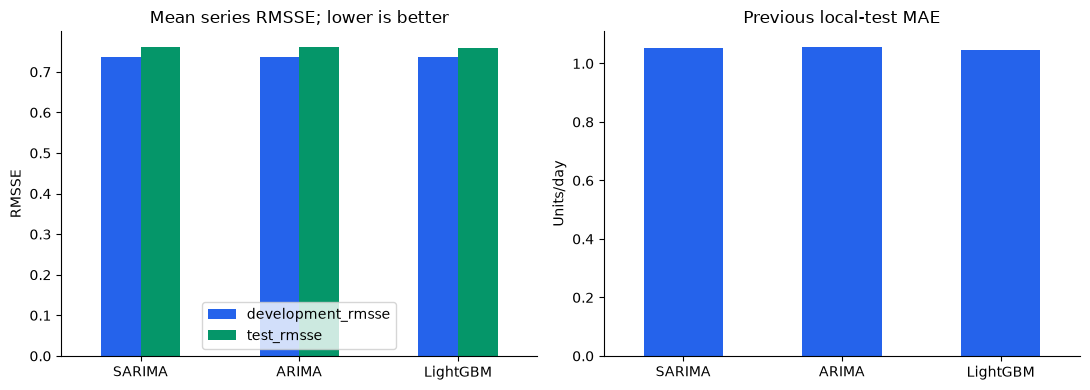

In [11]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
comparison[['development_rmsse','test_rmsse']].plot.bar(ax=axes[0],color=COLORS[:2])
axes[0].set(title='Mean series RMSSE; lower is better',xlabel='',ylabel='RMSSE')
comparison.test_mae.plot.bar(ax=axes[1],color=COLORS[0])
axes[1].set(title='Previous local-test MAE',xlabel='',ylabel='Units/day')
for ax in axes: ax.tick_params(axis='x',rotation=0)
save_figure(data,'comparison_01_three_models')


## Statistical fit diagnostics

In [12]:
optimized=diagnostics.status.ne('constant')
details=diagnostics.assign(optimized=optimized,converged_fit=optimized & diagnostics.converged,
                           constant=diagnostics.status.eq('constant'),
                           initialization_retry=diagnostics.status.isin(['diffuse_retry','optimizer_retry']))
convergence=details.groupby('model').agg(
    series_windows=('row','size'),optimized=('optimized','sum'),
    converged=('converged_fit','sum'),constant=('constant','sum'),
    initialization_retries=('initialization_retry','sum'),
    warnings=('warnings','sum'),negative_raw_forecasts=('negative_raw_forecasts','sum'))
convergence.to_csv(RESULTS / 'full_panel_fit_summary.csv')
display(convergence)
print('Constant histories receive exact constant forecasts; all series are included.')
print('Finite nonconverged fits remain explicitly flagged; negative forecasts are clipped to zero.')


,series_windows,optimized,converged,constant,initialization_retries,warnings,negative_raw_forecasts
model,,,,,,,
ARIMA,91470,91380,91325,90,1,308,115
SARIMA,91470,91380,91344,90,1,261,1325


Constant histories receive exact constant forecasts; all series are included.
Finite nonconverged fits remain explicitly flagged; negative forecasts are clipped to zero.


## Error by forecast day

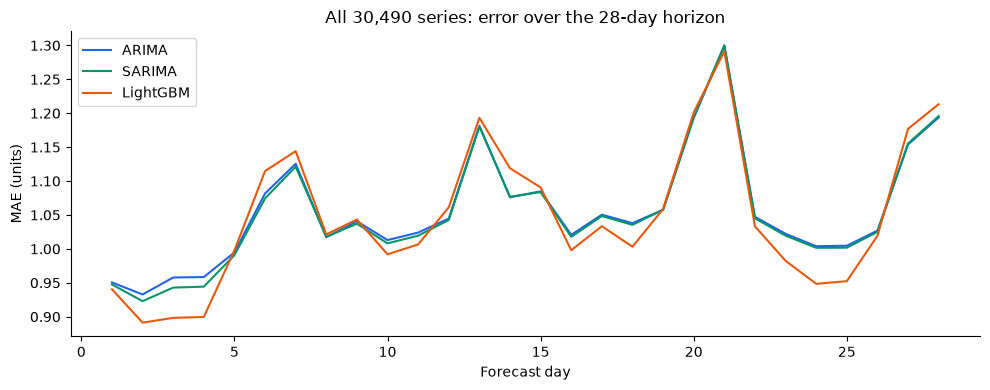

In [13]:
cutoff=config['test_cutoff']
actual=sales[panel_rows,cutoff:cutoff+28]
predictions={name:np.load(DATA / f'interim/full_panel_{name}_d{cutoff}.npy')
             for name in ['ARIMA','SARIMA','LightGBM']}
horizon=pd.DataFrame({name:np.abs(values-actual).mean(axis=0)
                      for name,values in predictions.items()},index=np.arange(1,29))
horizon.plot(figsize=(10,4),color=COLORS[:3])
plt.xlabel('Forecast day'); plt.ylabel('MAE (units)')
plt.title('All 30,490 series: error over the 28-day horizon')
save_figure(data,'comparison_02_horizon')


## Frequent sellers and forecast failure cases

Frequent sellers have positive sales on at least 95% of 90 training days before the first development window.
Choose the median-volume eligible series per category; retain the earlier examples to document failures.

In [14]:
selection_end=min(config['development_cutoffs'])
selection_history=sales[panel_rows,selection_end-90:selection_end]
selling_rate=(selection_history>0).mean(axis=1)
selection_mean=selection_history.mean(axis=1)
eligible=selling_rate>=0.95
frequent_examples=[]
for category in ['HOBBIES','HOUSEHOLD','FOODS']:
    candidates=np.flatnonzero(eligible & panel.cat_id.eq(category).to_numpy())
    ranked=candidates[np.argsort(selection_mean[candidates],kind='stable')]
    frequent_examples.append(int(ranked[len(ranked)//2]))
print(f'{eligible.sum():,} series sold on at least 95% of the preceding 90 days.')
display(panel.iloc[frequent_examples][['series_id','cat_id']].assign(
    selling_days=(selection_history[frequent_examples]>0).sum(axis=1),
    mean_units=selection_mean[frequent_examples]))


897 series sold on at least 95% of the preceding 90 days.


,series_id,cat_id,selling_days,mean_units
6346,HOBBIES_1_256_CA_3,HOBBIES,86,7.855556
28443,HOUSEHOLD_1_447_WI_3,HOUSEHOLD,89,6.600000
19989,FOODS_1_085_TX_3,FOODS,87,7.800000


In [15]:
ordered=panel.mean_training_sales.sort_values().index
examples=[ordered[0],ordered[len(ordered)//2],ordered[-1]]


In [16]:
example_records=[]
for position in dict.fromkeys([*frequent_examples,*examples]):
    history=sales[panel_rows[position],cutoff-728:cutoff].astype('float64')
    for name,values in predictions.items():
        errors=values[position]-actual[position].astype('float64')
        example_records.append(dict(series=panel.series_id.iloc[position],model=name,
            training_mean_728=history.mean(),training_mean_56=history[-56:].mean(),
            actual_mean=actual[position].mean(),forecast_mean=values[position].mean(),
            mae=np.abs(errors).mean(),rmse=np.sqrt(np.mean(errors**2))))
example_errors=pd.DataFrame(example_records)
display(example_errors.round(3))


,series,model,training_mean_728,training_mean_56,actual_mean,forecast_mean,mae,rmse
0,HOBBIES_1_256_CA_3,ARIMA,5.764,4.821,2.893,5.589000,3.624,4.159
1,HOBBIES_1_256_CA_3,SARIMA,5.764,4.821,2.893,5.669000,3.703,4.237
2,HOBBIES_1_256_CA_3,LightGBM,5.764,4.821,2.893,4.350000,3.153,3.646
3,HOUSEHOLD_1_447_WI_3,ARIMA,7.143,6.196,7.214,6.242000,3.162,4.244
4,HOUSEHOLD_1_447_WI_3,SARIMA,7.143,6.196,7.214,6.256000,3.176,4.252
5,HOUSEHOLD_1_447_WI_3,LightGBM,7.143,6.196,7.214,5.990000,3.172,4.269
6,FOODS_1_085_TX_3,ARIMA,6.022,8.964,11.464,9.643000,3.926,5.187
7,FOODS_1_085_TX_3,SARIMA,6.022,8.964,11.464,9.558000,3.917,5.214
8,FOODS_1_085_TX_3,LightGBM,6.022,8.964,11.464,8.521000,3.986,5.593
9,HOBBIES_1_124_WI_2,ARIMA,0.001,0.018,0.500,0.024000,0.510,1.024


In [17]:
import matplotlib.dates as mdates

def plot_example(ax,position):
    dates=calendar.date.iloc[cutoff:cutoff+28]
    history_dates=calendar.date.iloc[cutoff-56:cutoff]
    ax.plot(history_dates,sales[panel_rows[position],cutoff-56:cutoff],
            color='0.6',label='Observed history')
    ax.plot(dates,actual[position],color='black',label='Actual')
    errors=example_errors[example_errors.series.eq(panel.series_id.iloc[position])].set_index('model')
    for name,color in zip(['ARIMA','SARIMA','LightGBM'],COLORS):
        ax.plot(dates,predictions[name][position],color=color,
                label=f'{name} (MAE {errors.loc[name,"mae"]:.2f})')
    ax.axvline(dates.iloc[0],color='0.4',ls='--',lw=1)
    ax.set(title=panel.series_id.iloc[position],ylabel='Units/day')
    ax.legend(ncol=3,fontsize=8,loc='upper left')


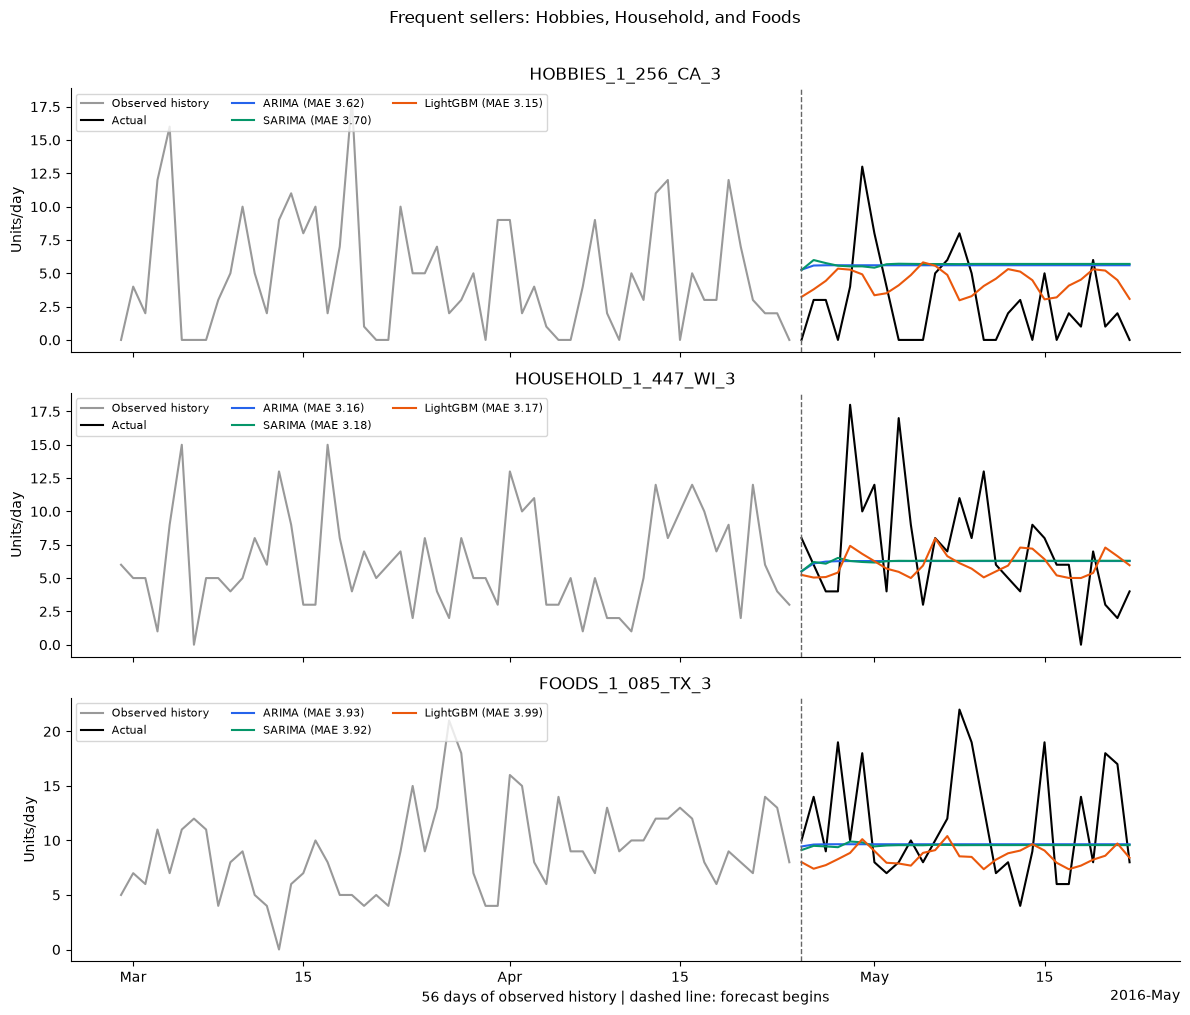

In [18]:
fig,axes=plt.subplots(3,1,figsize=(12,10),sharex=True)
for ax,position in zip(axes,frequent_examples):
    plot_example(ax,position)
locator=mdates.AutoDateLocator(minticks=5,maxticks=8)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[-1].set_xlabel('56 days of observed history | dashed line: forecast begins')
fig.suptitle('Frequent sellers: Hobbies, Household, and Foods',y=1.01)
save_figure(data,'comparison_04_frequent_sellers')


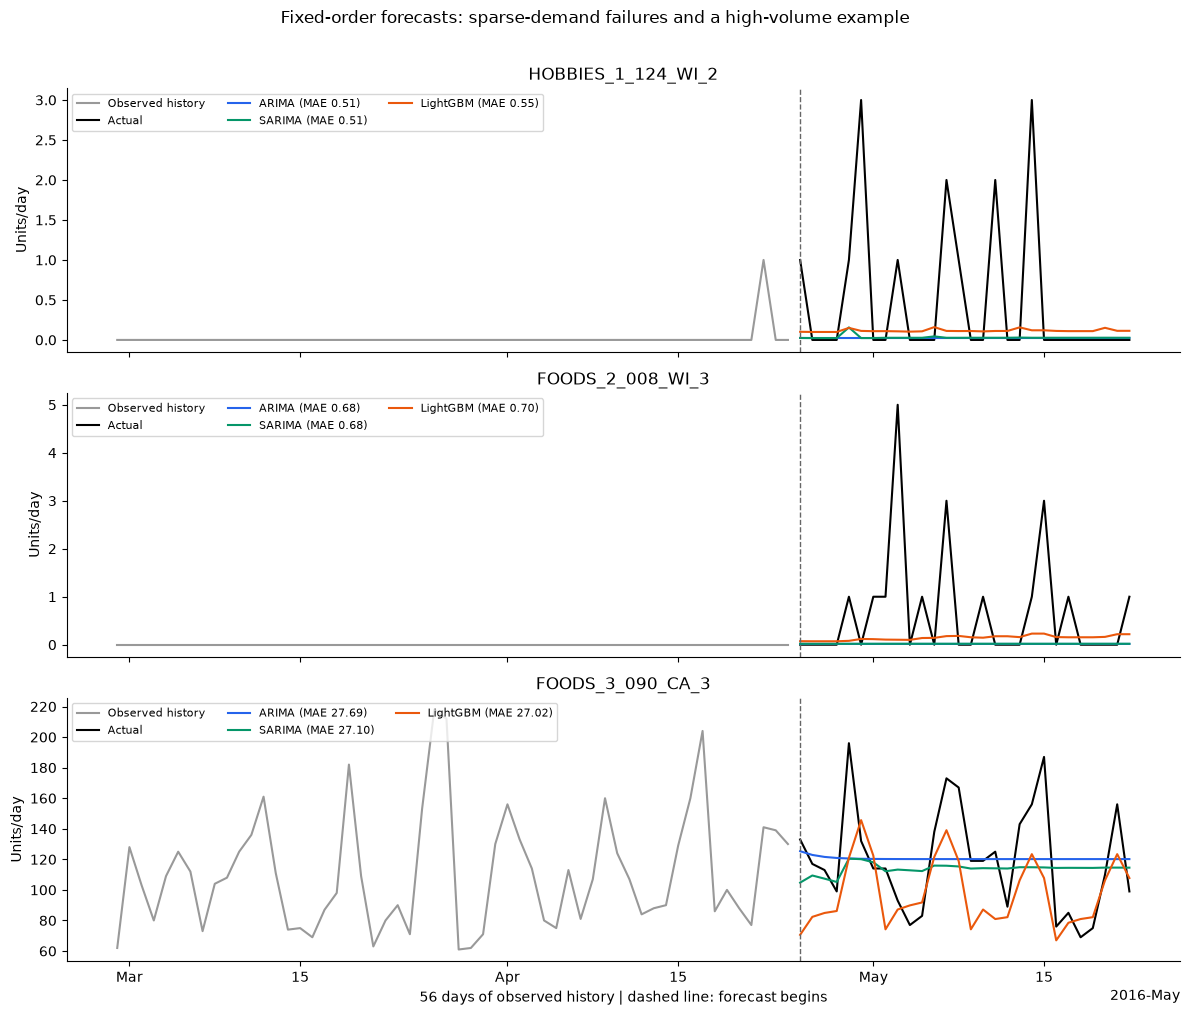

In [19]:
fig,axes=plt.subplots(3,1,figsize=(12,10),sharex=True)
for ax,position in zip(axes,examples):
    plot_example(ax,position)
locator=mdates.AutoDateLocator(minticks=5,maxticks=8)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[-1].set_xlabel('56 days of observed history | dashed line: forecast begins')
fig.suptitle('Fixed-order forecasts: sparse-demand failures and a high-volume example',y=1.01)
save_figure(data,'comparison_03_forecasts')


## Model summary for the README

In [20]:
model_summary="""## Model summary

| Model | Specification | Approach |
| --- | --- | --- |
| ARIMA | ARIMA(1,1,1) | Models each series without an explicit seasonal component. |
| SARIMA | SARIMA(1,1,1)(1,0,0,7) | Adds a weekly seasonal component to each series. |
| LightGBM | 200 trees, 31 leaves, learning rate 0.05 | Uses calendar and lag features to correct a recent weekday-average forecast. |

ARIMA and SARIMA each fit all 30,490 series using 728 recent daily observations.
LightGBM learns across all 30,490 series using temporally sampled training targets.
"""


## Evaluation table for the README

In [21]:
readable=comparison.rename(columns={
    'development_rmsse':'Development RMSSE', 'test_rmsse':'Local-test RMSSE',
    'test_mae':'Local-test MAE', 'test_rmse':'Local-test RMSE'})
header='| Model | '+' | '.join(readable.columns)+' |'
separator='| '+' | '.join(['---']*(len(readable.columns)+1))+' |'
rows=['| '+name+' | '+' | '.join(f'{x:.4f}' for x in row)+' |'
      for name,row in readable.iterrows()]
evaluation_table='\n'.join([header,separator,*rows])


In [22]:
start_date=calendar.date.iloc[config['test_cutoff']].strftime('%Y-%m-%d')
end_date=calendar.date.iloc[config['test_cutoff']+27].strftime('%Y-%m-%d')
fit_count=int(convergence.optimized.sum())
converged_count=int(convergence.converged.sum())
constant_count=int(convergence.constant.sum())
coverage=int(scores.loc[scores.phase.eq('local_test'),'rmsse_series'].min())
evaluation_intro=f"""## Evaluation

All three models forecast **{len(panel):,} product/store series** for **28 days**.
Two development windows precede the local test, **{start_date} to {end_date}**.
The previously inspected local test makes this a retrospective comparison.
MAE/RMSE cover every series; mean RMSSE covers {coverage:,} series with defined training scales.
{converged_count:,}/{fit_count:,} optimized statistical fits converged;
{constant_count:,} constant-history windows receive exact constant forecasts.
"""


## Comparison graphs for the README

In [23]:
graphs="""## Comparison graphs

### Model scores

![ARIMA, SARIMA, and LightGBM scores](reports/figures/comparison_01_three_models.png)

### Error across the forecast horizon

![MAE by forecast day](reports/figures/comparison_02_horizon.png)
"""


In [24]:
forecast_graph=f"""### Frequent-seller forecasts

{eligible.sum():,} product/store series sold on at least 95% of the 90 days before
the first development window. The examples are the median-volume eligible series
within each category, selected without forecast-period outcomes. All three models
already forecast these products. Grey lines show 56 days of observed history.

![Frequent sellers: observed history and three-model forecasts](reports/figures/comparison_04_frequent_sellers.png)
"""


In [25]:
forecast_graph+="""### Sparse-demand and high-volume failure cases

The earlier low-, median-, and high-volume examples remain below. HOBBIES_1_124_WI_2
had one sale in its 728-day training window; FOODS_2_008_WI_3 had no sales in its
last 56 training days. All models miss their subsequent recovery. Zero sales alone
cannot establish the reason. For FOODS_3_090_CA_3, LightGBM slightly improves MAE,
but SARIMA has lower RMSE. Fixed statistical orders flatten over the horizon.
![Earlier examples and forecast limitations](reports/figures/comparison_03_forecasts.png)
"""


## Final comparison in the README

In [26]:
rmsse_winner=comparison.test_rmsse.idxmin()
mae_winner=comparison.test_mae.idxmin()
rmse_winner=comparison.test_rmse.idxmin()
if len({rmsse_winner,mae_winner,rmse_winner})==1:
    result_line=f'**{rmsse_winner}** has the lowest local-test mean RMSSE, MAE, and RMSE.'
else:
    result_line=f'**{rmsse_winner}** leads mean RMSSE, **{mae_winner}** MAE, and **{rmse_winner}** RMSE.'
development_winner=comparison.development_rmsse.idxmin()
conclusion=f"""## Final comparison

{result_line} **{development_winner}** has the lowest average development RMSSE.
These scores and graphs cover all **30,490 series**, using fixed model settings
and common forecast windows.
"""


In [27]:
intro="""# Retail Sales Forecasting: ARIMA, SARIMA, and LightGBM

A retail time series study using M5 sales data to compare statistical forecasting
with machine learning over a 28-day horizon.
"""
readme='\n\n'.join(section.strip() for section in [
    intro,model_summary,evaluation_intro,evaluation_table,graphs,forecast_graph,conclusion])+'\n'
(ROOT / 'README.md').write_text(readme)
print('Updated README.md with model summaries, evaluation, and comparison graphs.')


Updated README.md with model summaries, evaluation, and comparison graphs.
